# Курс по прогнозированию временных рядов

# Неделя 7

# Прогнозирование веб-трафика с помощью ридж-регрессии

Forecasting web traffic with machine learning by Joaquín Amat Rodrigo and Javier Escobar Ortiz, available under Attribution-NonCommercial-ShareAlike 4.0 International (CC BY-NC-SA 4.0 DEED) at https://cienciadedatos.net/documentos/py37-forecasting-visitas-web-machine-learning.html


История ежедневных посещений сайта cienciadedatos.net доступна с 07.01.2020. Цель — создать модель прогнозирования, способную предсказывать трафик сайта в течение следующих 7 дней. Пользователь хочет иметь возможность запускать модель каждый понедельник и получать ежедневные прогнозы трафика на оставшуюся часть недели.

Для оценки производительности модели в соответствии с ее предполагаемым использованием целесообразно не прогнозировать только последние 7 дней временного ряда, а моделировать весь процесс.

В этом примере используется стратегия бэктестинга с переобучением и увеличением размера обучающей выборки (кросс-валидация расширяющимся окном). Внутри функция применяет следующий процесс.

В первой итерации модель обучается на основе наблюдений, выбранных для первоначального обучения. Затем прогнозируются следующие 7 наблюдений (1 неделя).

Во второй итерации модель переобучается путем добавления 7 наблюдений к первоначальному обучающему набору, а затем прогнозируются следующие 7 наблюдений (1 неделя).

Этот процесс повторяется до тех пор, пока не будут использованы все доступные наблюдения. Следуя этой стратегии, обучающий набор увеличивается в каждой итерации на столько наблюдений, сколько шагов прогнозируется.

In [35]:
# Data processing
# ==============================================================================
import numpy as np
import pandas as pd
from skforecast.datasets import fetch_dataset

# Plots
# ==============================================================================
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import plotly.graph_objects as go
import plotly.io as pio
import plotly.offline as poff
pio.templates.default = "seaborn"
poff.init_notebook_mode(connected=True)
plt.style.use('seaborn-v0_8-darkgrid')

# Modelling and forecasting
# ==============================================================================
import skforecast
import sklearn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from skforecast.recursive import ForecasterRecursive, ForecasterEquivalentDate
from skforecast.model_selection import TimeSeriesFold, grid_search_forecaster, backtesting_forecaster
from skforecast.stats import calculate_lag_autocorrelation
import shap

# Warnings config
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

color = '\033[1m\033[38;5;208m'
print(f"{color}Version skforecast: {skforecast.__version__}")
print(f"{color}Version scikit-learn: {sklearn.__version__}")
print(f"{color}Version pandas: {pd.__version__}")
print(f"{color}Version numpy: {np.__version__}")

Version skforecast: 0.26.0
Version scikit-learn: 1.7.2
Version pandas: 2.3.3
Version numpy: 1.26.4


Данные

In [36]:
# Data downloading
# ==============================================================================
data = fetch_dataset(name="website_visits", raw=True)

╭───────────────────────────── website_visits ──────────────────────────────╮
│ Description:                                                              │
│ Daily visits to the cienciadedatos.net website registered with the google │
│ analytics service.                                                        │
│                                                                           │
│ Source:                                                                   │
│ Amat Rodrigo, J. (2021). cienciadedatos.net (1.0.0). Zenodo.              │
│ https://doi.org/10.5281/zenodo.10006330                                   │
│                                                                           │
│ URL:                                                                      │
│ https://raw.githubusercontent.com/skforecast/skforecast-                  │
│ datasets/main/data/visitas_por_dia_web_cienciadedatos.csv                 │
│                                                                           │
│ Shape: 421 rows x 2 columns                                               │
╰───────────────────────────────────────────────────────────────────────────╯

Дата в столбце хранится как объект. Она преобразуется в тип datetime с помощью функции pd.to_datetime().  Частота устанавливается равной 1 дню.

In [37]:
# Data preprocessing
# ==============================================================================
data['date'] = pd.to_datetime(data['date'], format='%d/%m/%y')
data = data.set_index('date')
data = data.asfreq('1D')
data = data.sort_index()
data.head(3)

,users
date,
2020-07-01,2324
2020-07-02,2201
2020-07-03,2146


In [38]:
# Check index is complete and there are not missing values
# ==============================================================================
start_date = data.index.min()
end_date = data.index.max()
complete_date_range = pd.date_range(start=start_date, end=end_date, freq=data.index.freq)
is_index_complete = (data.index == complete_date_range).all()
print(f"Index complete: {is_index_complete}")
print(f"Number of rows with missing values: {data.isnull().any(axis=1).mean()}")

Index complete: True
Number of rows with missing values: 0.0


Набор данных (начинается 01.07.2020 и заканчивается 22.08.2021) разделен на 3 части: одна для обучения, одна для валидации и одна для тестирования.

In [39]:
# Split data: train-validation-test
# ==============================================================================
end_train = '2021-03-30 23:59:00'
end_validation = '2021-06-30 23:59:00'
data_train = data.loc[: end_train, :]
data_val   = data.loc[end_train:end_validation, :]
data_test  = data.loc[end_validation:, :]
print(f"Training dates   : {data_train.index.min()} --- {data_train.index.max()}  (n={len(data_train)})")
print(f"Validation dates : {data_val.index.min()} --- {data_val.index.max()}  (n={len(data_val)})")
print(f"Test dates       : {data_test.index.min()} --- {data_test.index.max()}  (n={len(data_test)})")

Training dates   : 2020-07-01 00:00:00 --- 2021-03-30 00:00:00  (n=273)
Validation dates : 2021-03-31 00:00:00 --- 2021-06-30 00:00:00  (n=92)
Test dates       : 2021-07-01 00:00:00 --- 2021-08-25 00:00:00  (n=56)


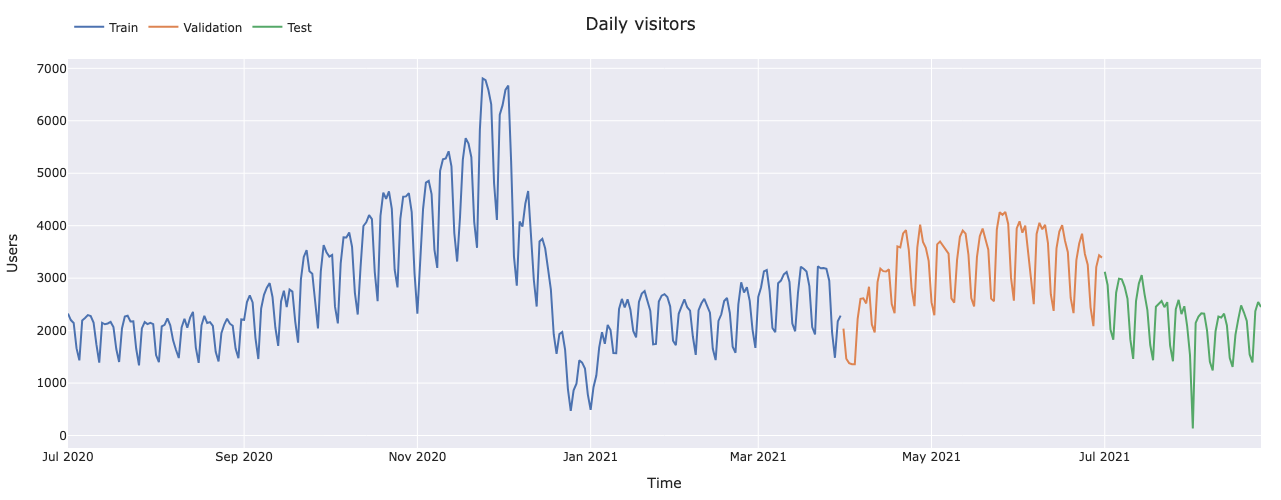

In [40]:
# Interactive plot of time series
# ==============================================================================
fig = go.Figure()
fig.add_trace(go.Scatter(x=data_train.index, y=data_train['users'], mode='lines', name='Train'))
fig.add_trace(go.Scatter(x=data_val.index, y=data_val['users'], mode='lines', name='Validation'))
fig.add_trace(go.Scatter(x=data_test.index, y=data_test['users'], mode='lines', name='Test'))
fig.update_layout(
    title  = 'Daily visitors',
    xaxis_title="Time",
    yaxis_title="Users",
    width=1000,
    height=500,
    margin=dict(l=20, r=20, t=35, b=20),
    legend=dict(orientation="h", yanchor="top", y=1.12, xanchor="left", x=0.001)
)
fig.show()

### Анализ сезонности

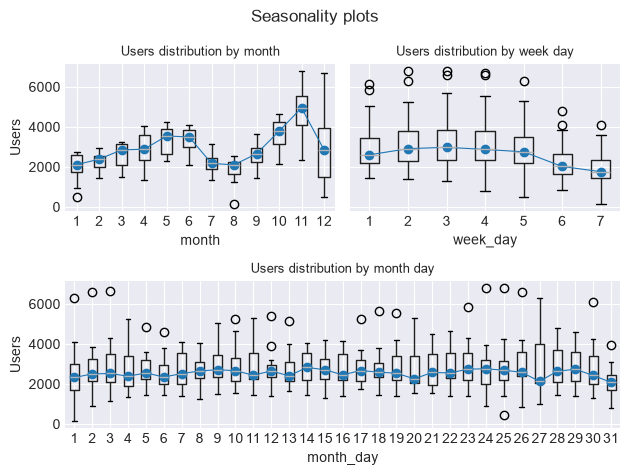

In [41]:
fig, axs = plt.subplot_mosaic(
                """
                    AB
                    CC
                """,
                sharey=True
            )

# Users distribution by month
data['month'] = data.index.month
data.boxplot(column='users', by='month', ax=axs['A'])
data.groupby('month')['users'].median().plot(style='o-', linewidth=0.8, ax=axs['A'])
axs['A'].set_ylabel('Users')
axs['A'].set_title('Users distribution by month', fontsize=9)

# Users distribution by week day
data['week_day'] = data.index.day_of_week + 1
data.boxplot(column='users', by='week_day', ax=axs['B'])
data.groupby('week_day')['users'].median().plot(style='o-', linewidth=0.8, ax=axs['B'])
axs['B'].set_ylabel('Users')
axs['B'].set_title('Users distribution by week day', fontsize=9)

# Users distribution by month day
data['month_day'] = data.index.day
data.boxplot(column='users', by='month_day', ax=axs['C'])
data.groupby('month_day')['users'].median().plot(style='o-', linewidth=0.8, ax=axs['C'])
axs['C'].set_ylabel('Users')
axs['C'].set_title('Users distribution by month day', fontsize=9)

fig.suptitle("Seasonality plots", fontsize=12)
fig.tight_layout()

Невозможно определить наличие годовой сезонности, поскольку данные не охватывают два года.

Наблюдается еженедельная сезонность, с уменьшением веб-трафика в выходные дни.

### Диаграммы автокорреляции

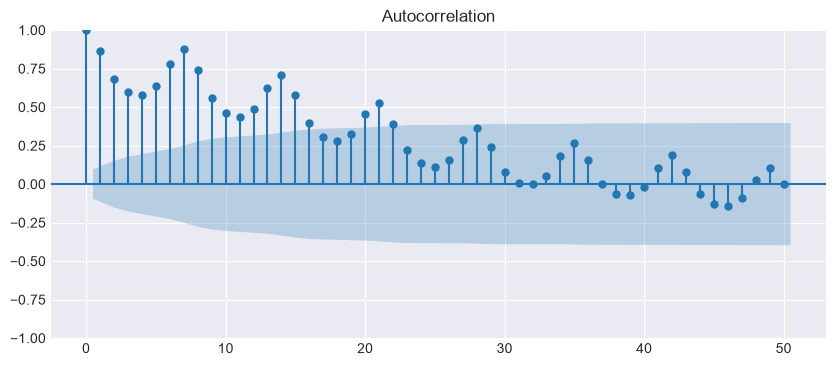

In [42]:
# Autocorrelation plot
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(data['users'], ax=ax, lags=50, fft=True)
plt.show()

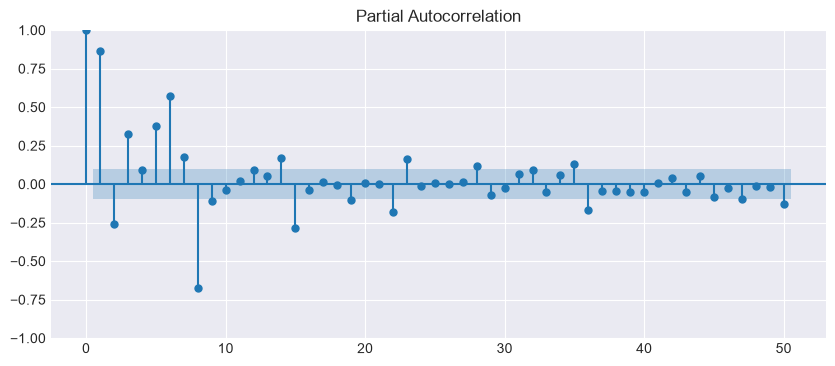

In [43]:
# Partial autocorrelation plot
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(data['users'], ax=ax, lags=50, method='burg')
plt.show()

In [45]:
# Top 10 lags with the highest absolute partial autocorrelation
# ==============================================================================
calculate_lag_autocorrelation(
    data        = data['users'],
    n_lags      = 60,
    sort_by     = "partial_autocorrelation_abs",
).head(10)

,lag,partial_autocorrelation_abs,partial_autocorrelation,autocorrelation_abs,autocorrelation
0,1,0.865897,0.865897,0.865897,0.865897
1,8,0.660998,-0.660998,0.739243,0.739243
2,6,0.558165,0.558165,0.782706,0.782706
3,5,0.376389,0.376389,0.636391,0.636391
4,3,0.325238,0.325238,0.598038,0.598038
5,15,0.275001,-0.275001,0.577816,0.577816
6,2,0.259590,-0.259590,0.684822,0.684822
7,22,0.168378,-0.168378,0.392733,0.392733
8,23,0.154417,0.154417,0.221251,0.221251
9,7,0.152392,0.152392,0.874265,0.874265


Графики автокорреляции и частичной автокорреляции показывают четкую взаимосвязь между количеством пользователей в определенный день и в предыдущие дни. Это свидетельствует о том, что авторегрессионные модели могут обеспечивать хорошие прогнозы.

## Базовая модель

Сезонный наивный прогноз.

In [46]:
# Create baseline: value of the previous day
# ==============================================================================
forecaster = ForecasterEquivalentDate(
                 offset    = pd.DateOffset(days=1),
                 n_offsets = 1
             )

# Train forecaster
# ==============================================================================
forecaster.fit(y=data.loc[:end_validation, 'users'])
forecaster

======================== 
ForecasterEquivalentDate 
======================== 
Offset: <DateOffset: days=1> 
Number of offsets: 1 
Aggregation function: mean 
Window size: 1 
Series name: users 
Training range: [Timestamp('2020-07-01 00:00:00'), Timestamp('2021-06-30 00:00:00')] 
Training index type: DatetimeIndex 
Training index frequency: <Day> 
Creation date: 2026-10-13 17:32:01 
Last fit date: 2026-10-13 17:32:01 
Skforecast version: 0.26.0 
Python version: 3.11.11 
Forecaster id: None

In [47]:
# Backtesting
# ==============================================================================
cv = TimeSeriesFold(
        steps              = 7,
        initial_train_size = len(data.loc[:end_validation]),
        refit              = False,
      )
metric_baseline, predictions = backtesting_forecaster(
                                   forecaster = forecaster,
                                   y          = data['users'],
                                   cv         = cv,
                                   metric     = 'mean_absolute_error'
                               )
metric_baseline

  0%|          | 0/8 [00:00<?, ?it/s]

,mean_absolute_error
0,513.035714


Средняя ошибка - 513 пользователей.

## Авторегрессионная модель

Авторегрессионная модель (ForecasterRecursive) обучается с использованием линейной модели с ридж регуляризацией.

Для ридж-регрессии требуется стандартизация данных. Используем StandarScaler.

In [48]:
# Create forecaster
# ==============================================================================
forecaster = ForecasterRecursive(
                 estimator     = Ridge(random_state=123),
                 lags          = 14,
                 transformer_y = StandardScaler(),
                 forecaster_id = 'web_traffic'
             )

Настройка гиперпараметров поиском по сетке

In [49]:
# Grid search of hyper-parameters
# ==============================================================================
# Estimator's hyper-parameters
param_grid = {'alpha': np.logspace(-3, 3, 10)}

# Lags used as predictors
lags_grid = [7, 14, 21, [7, 14, 21]]

# Folds
cv = TimeSeriesFold(
        steps              = 7,
        initial_train_size = len(data_train),
        refit              = False,
      )

results_search = grid_search_forecaster(
                   forecaster = forecaster,
                   y          = data.loc[:end_validation, 'users'],
                   param_grid = param_grid,
                   lags_grid  = lags_grid,
                   cv         = cv,
                   metric     = 'mean_absolute_error'
               )

best_params = results_search['params'].iat[0]
results_search.head()

lags grid:   0%|          | 0/4 [00:00<?, ?it/s]

params grid:   0%|          | 0/10 [00:00<?, ?it/s]

params grid:   0%|          | 0/10 [00:00<?, ?it/s]

params grid:   0%|          | 0/10 [00:00<?, ?it/s]

params grid:   0%|          | 0/10 [00:00<?, ?it/s]

,lags,lags_label,params,mean_absolute_error,alpha
0,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",{'alpha': 2.154434690031882},214.791677,2.154435
1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",{'alpha': 0.46415888336127775},216.551409,0.464159
2,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",{'alpha': 0.1},217.770757,0.100000
3,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",{'alpha': 0.021544346900318832},218.127429,0.021544
4,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",{'alpha': 0.004641588833612777},218.206475,0.004642


Наилучшие результаты достигаются при использовании лагов [1 2 3 4 5 6 7 8 9 10 11 12 13 14] и конфигурации Ridge {'alpha': 2.154}. Указав `return_best = True` в функции `grid_search_forecaster()` модель автоматически переобучается с использованием наилучшей конфигурации и всего набора данных.

In [50]:
forecaster

=================== 
ForecasterRecursive 
=================== 
Estimator: Ridge 
Lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14] 
Window features: None 
Calendar features: None 
Window size: 14 
Series name: users 
Exogenous included: False 
Exogenous names: None 
Categorical features: auto 
Transformer for y: StandardScaler() 
Transformer for exog: None 
Weight function included: False 
Differentiation order: None 
Drop NaN from series: False 
Training range: [Timestamp('2020-07-01 00:00:00'), Timestamp('2021-06-30 00:00:00')] 
Training index type: DatetimeIndex 
Training index frequency: <Day> 
Estimator parameters: 
    {'alpha': 2.154434690031882, 'copy_X': True, 'fit_intercept': True, 'max_iter':
    None, 'positive': False, 'random_state': 123, 'solver': 'auto', 'tol':
    0.0001} 
fit_kwargs: {} 
Creation date: 2026-10-13 17:32:03 
Last fit date: 2026-10-13 17:32:05 
Skforecast version: 0.26.0 
Python version: 3.11.11 
Forecaster id: web_traffic

In [51]:
# Backtest final model using test data
# ==============================================================================
cv = TimeSeriesFold(
        steps              = 7,
        initial_train_size = len(data.loc[:end_validation]),
        refit              = True,
        fixed_train_size   = False,
      )
metric, predictions = backtesting_forecaster(
                          forecaster = forecaster,
                          y          = data.users,
                          cv         = cv,
                          metric     = 'mean_absolute_error',
                          verbose    = True,
                      )
metric

Information of folds
--------------------
Number of observations used for initial training: 365
Number of observations used for backtesting: 56
    Number of folds: 8
    Number skipped folds: 0 
    Number of steps per fold: 7
    Number of steps to exclude between last observed data (last window) and predictions (gap): 0

Fold: 0
    Training:   2020-07-01 00:00:00 -- 2021-06-30 00:00:00  (n=365)
    Validation: 2021-07-01 00:00:00 -- 2021-07-07 00:00:00  (n=7)
Fold: 1
    Training:   2020-07-01 00:00:00 -- 2021-07-07 00:00:00  (n=372)
    Validation: 2021-07-08 00:00:00 -- 2021-07-14 00:00:00  (n=7)
Fold: 2
    Training:   2020-07-01 00:00:00 -- 2021-07-14 00:00:00  (n=379)
    Validation: 2021-07-15 00:00:00 -- 2021-07-21 00:00:00  (n=7)
Fold: 3
    Training:   2020-07-01 00:00:00 -- 2021-07-21 00:00:00  (n=386)
    Validation: 2021-07-22 00:00:00 -- 2021-07-28 00:00:00  (n=7)
Fold: 4
    Training:   2020-07-01 00:00:00 -- 2021-07-28 00:00:00  (n=393)
    Validation: 2021-07-29 00:

  0%|          | 0/8 [00:00<?, ?it/s]

,mean_absolute_error
0,211.974974


## Экзогенные факторы

В предыдущем примере в качестве предикторов использовались только лаги целевой переменной. Лобавим каленндарные признаки.

In [52]:
# Features based on calendar
# ==============================================================================
data['month'] = data.index.month
data['month_day'] = data.index.day
data['week_day'] = data.index.day_of_week
data.head()

,users,month,week_day,month_day
date,,,,
2020-07-01,2324,7,2,1
2020-07-02,2201,7,3,2
2020-07-03,2146,7,4,3
2020-07-04,1666,7,5,4
2020-07-05,1433,7,6,5


In [53]:
# One hot encoding transformer
# ==============================================================================
one_hot_encoder = make_column_transformer(
    (
        OneHotEncoder(sparse_output=False, drop='if_binary'),
        ['month', 'week_day', 'month_day'],
    ),
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

data = one_hot_encoder.fit_transform(data)
data.head()

,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,...,month_day_23,month_day_24,month_day_25,month_day_26,month_day_27,month_day_28,month_day_29,month_day_30,month_day_31,users
date,,,,,,,,,,,,,,,,,,,,,
2020-07-01,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2324
2020-07-02,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2201
2020-07-03,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2146
2020-07-04,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1666
2020-07-05,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1433


In [54]:
# Split data train-val-test
# ==============================================================================
data_train = data.loc[: end_train, :]
data_val   = data.loc[end_train:end_validation, :]
data_test  = data.loc[end_validation:, :]
exog_features = [col for col in data.columns if col.startswith(('month_', 'week_day_', 'month_day_'))]

In [55]:
# Create forecaster
# ==============================================================================
forecaster = ForecasterRecursive(
                 estimator     = Ridge(**best_params, random_state=123),
                 lags          = 14,
                 transformer_y = StandardScaler(),
                 forecaster_id = 'web_traffic'
             )

# Backtest forecaster with exogenous features
# ==============================================================================
metric, predictions = backtesting_forecaster(
                          forecaster = forecaster,
                          y          = data.users,
                          exog       = data[exog_features],
                          cv         = cv,
                          metric     = 'mean_absolute_error'
                      )

predictions.head(5)

  0%|          | 0/8 [00:00<?, ?it/s]

,fold,pred
2021-07-01,0,3109.259189
2021-07-02,0,2914.336919
2021-07-03,0,2318.810952
2021-07-04,0,1957.766737
2021-07-05,0,3002.216742


In [56]:
display(metric)

,mean_absolute_error
0,149.058991


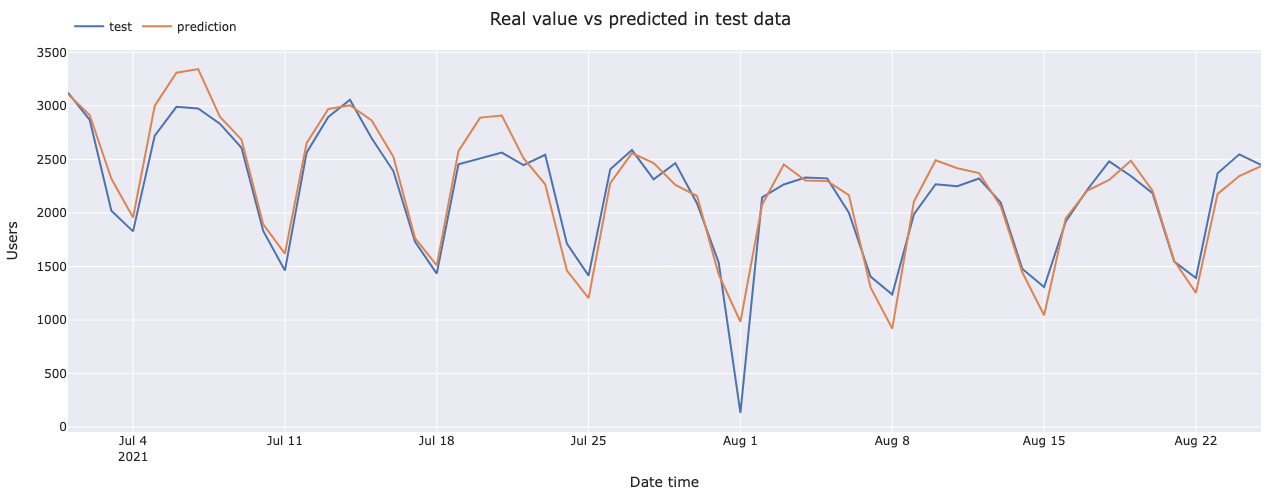

In [57]:
# Plot predictions vs real value
# ======================================================================================
fig = go.Figure()
trace1 = go.Scatter(x=data_test.index, y=data_test['users'], name="test", mode="lines")
trace2 = go.Scatter(x=predictions.index, y=predictions['pred'], name="prediction", mode="lines")
fig.add_trace(trace1)
fig.add_trace(trace2)
fig.update_layout(
    title="Real value vs predicted in test data",
    xaxis_title="Date time",
    yaxis_title="Users",
    width=1000,
    height=500,
    margin=dict(l=20, r=20, t=35, b=20),
    legend=dict(orientation="h", yanchor="top", y=1.1, xanchor="left", x=0.001)
)
fig.show()

In [58]:
# Create and train forecaster with the best hyperparameters and lags found
# ==============================================================================
forecaster = ForecasterRecursive(
                 estimator     = Ridge(**best_params, random_state=123),
                 lags          = 14,
                 transformer_y = StandardScaler(),
                 forecaster_id = 'web_traffic'
             )
forecaster.fit(y=data['users'], exog=data[exog_features], store_in_sample_residuals=True)

## Важность признаков

In [59]:
# Extract feature importance
# ==============================================================================
importance = forecaster.get_feature_importances()
importance.head(10)

,feature,importance
0,lag_1,0.753168
26,week_day_0,0.411202
5,lag_6,0.230151
24,month_11,0.195164
6,lag_7,0.166955
30,week_day_4,0.096308
2,lag_3,0.092973
55,month_day_23,0.091812
35,month_day_3,0.090239
23,month_10,0.086671


### Shap values

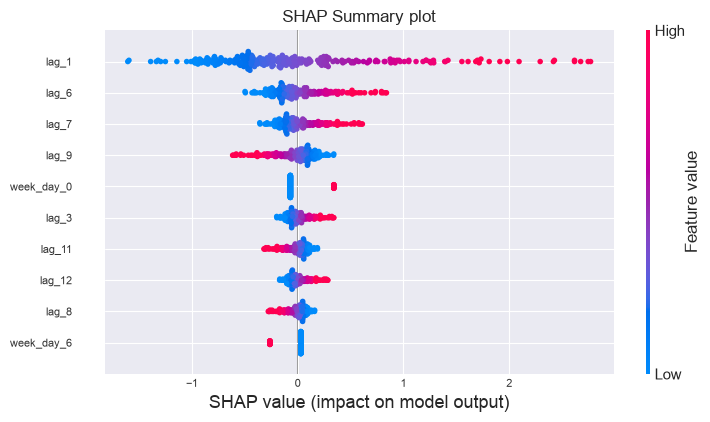

In [60]:
# Training matrices used by the forecaster to fit the internal estimator
# ==============================================================================
X_train, y_train = forecaster.create_train_X_y(
                        y    = data_train['users'],
                        exog = data_train[exog_features]
                    )

# Create SHAP explainer (for linear models)
# ==============================================================================
explainer = shap.LinearExplainer(forecaster.estimator, X_train)
shap_values = explainer.shap_values(X_train)

# Shap summary plot (top 10)
# ==============================================================================
shap.initjs()
shap.summary_plot(shap_values, X_train, max_display=10, show=False)
fig, ax = plt.gcf(), plt.gca()
ax.set_title("SHAP Summary plot")
ax.tick_params(labelsize=8)
fig.set_size_inches(8, 4)

### Прогнозные интервалы

Получены с помощью бутстрепа остатков (residual bootstrap)..

Процесс построения интервала состоит из следующих шагов:
1. Сбор остатков (Residuals):
Во время обучения модели (или на валидационной выборке, если использовать out-of-sample residuals) библиотека вычисляет ошибки прогноза — разницу между реальными значениями и предсказаниями модели. Эти ошибки сохраняются в памяти форкастера.
2. Точечный прогноз:
Для будущего периода строится обычный точечный прогноз (колонка pred).
3. Имитационное моделирование (Bootstrapping):
Чтобы оценить неопределенность, библиотека генерирует n_boot (в вашем коде это 250) различных сценариев (путей) развития событий. Для каждого сценария происходит следующее:
  - На каждом шаге прогноза из сохраненных остатков случайным образом (с возвращением) выбирается один остаток.
  - Этот случайный остаток прибавляется к точечному прогнозу.
  - Важный нюанс для рекурсивных моделей: Поскольку прогноз на следующий шаг зависит от предыдущего, в качестве "фактического" значения для следующего шага используется не просто точечный прогноз, а именно это новое смоделированное значение (прогноз + случайный остаток).
  - Так моделируется целая траектория на всю длину прогноза.
4. Расчет интервала:
После того как сгенерировано 250 различных траекторий, для каждого шага времени библиотека смотрит на распределение этих 250 значений. Поскольку вы указали interval=[10, 90], алгоритм вычисляет 10-й перцентиль (нижняя граница) и 90-й перцентиль (верхняя граница) из этих 250 симуляций.

Позже на 9-й неделе мы поговорим об этом подробнее.

In [61]:
# Backtest with prediction intervals
# ==============================================================================
metric, predictions = backtesting_forecaster(
                            forecaster = forecaster,
                            y          = data.users,
                            exog       = data[exog_features],
                            cv         = cv,
                            metric     = 'mean_absolute_error',
                            interval   = [0.1, 0.9],
                            n_boot     = 250
                       )
display(metric)
predictions.head(5)

  0%|          | 0/8 [00:00<?, ?it/s]

,mean_absolute_error
0,149.058991


,fold,pred,lower_bound,upper_bound
2021-07-01,0,3109.259189,3004.224962,3310.050325
2021-07-02,0,2914.336919,2664.338306,3208.135842
2021-07-03,0,2318.810952,2004.743839,2578.830978
2021-07-04,0,1957.766737,1657.452071,2174.728528
2021-07-05,0,3002.216742,2608.296170,3294.607486


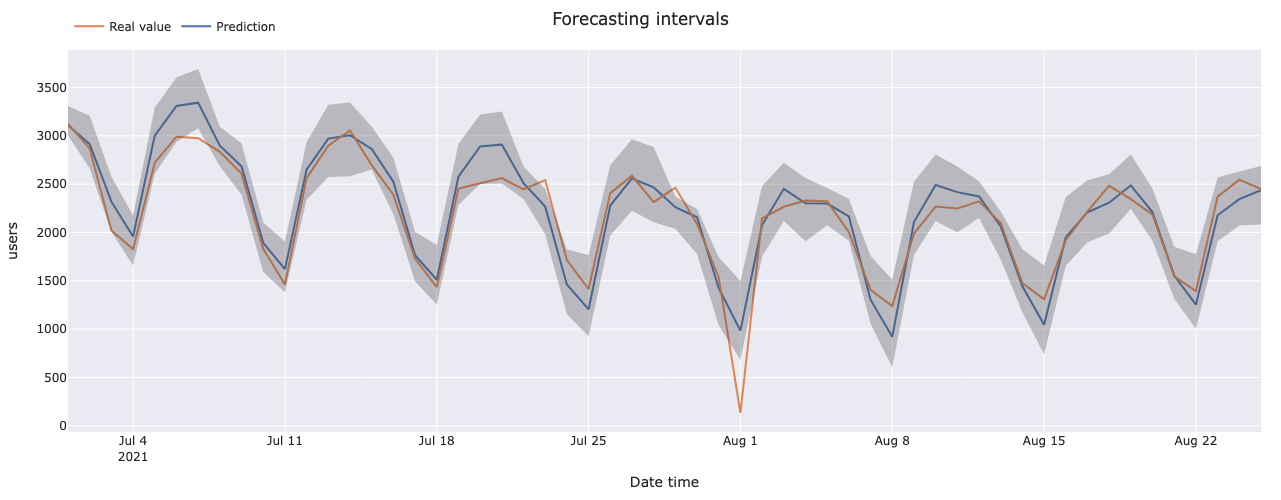

In [62]:
# Plot prediction intervals vs real value
# ==============================================================================
fig = go.Figure([
    go.Scatter(
        name='Prediction',
        x=predictions.index,
        y=predictions['pred'],
        mode='lines',
    ),
    go.Scatter(
        name='Real value',
        x=data_test.index,
        y=data_test.loc[:, 'users'],
        mode='lines',
    ),
    go.Scatter(
        name='Upper Bound',
        x=predictions.index,
        y=predictions['upper_bound'],
        mode='lines',
        marker=dict(color="#444"),
        line=dict(width=0),
        showlegend=False
    ),
    go.Scatter(
        name='Lower Bound',
        x=predictions.index,
        y=predictions['lower_bound'],
        marker=dict(color="#444"),
        line=dict(width=0),
        mode='lines',
        fillcolor='rgba(68, 68, 68, 0.3)',
        fill='tonexty',
        showlegend=False
    )
])
fig.update_layout(
    title="Forecasting intervals",
    xaxis_title="Date time",
    yaxis_title="users",
    width=1000,
    height=500,
    margin=dict(l=20, r=20, t=35, b=20),
    hovermode="x",
    legend=dict(orientation="h", yanchor="top", y=1.1, xanchor="left", x=0.001)
)
fig.show()